# **TP 16 — Segmentation du catalogue et moteur de substitution**

*Projet fil rouge NutriScope · séance du mercredi 28/10 · journée*

## **Introduction**

### Qu'est-ce que la segmentation et la substitution dans NutriScope ?

La promesse de NutriScope tient en une phrase : « *voici un produit comparable, mais mieux noté* ». Pour la tenir, il faut résoudre deux problèmes l'un après l'autre.

1. **Segmenter le catalogue** : regrouper les produits qui se ressemblent sur le plan nutritionnel, pour comprendre ce que contient réellement notre base.
2. **Substituer** : pour un produit scanné, trouver des alternatives *comparables* (même usage, profil proche) mais *mieux notées* au Nutri-Score.

**Analogie :** Imaginez un pharmacien-conseil qui connaît parfaitement son rayon. Face à un client qui tient une boîte, il ne lui propose pas n'importe quoi : il reste dans la même famille de produits, choisit ce qui s'en rapproche le plus, et écarte tout ce qui serait absurde (un soda pour remplacer un biscuit). Notre moteur doit se comporter comme lui, avec des **règles de garde** explicites.

**Ce que vous allez faire aujourd'hui :**

1. **Préparer** les nutriments du catalogue (valeurs manquantes, asymétries, normalisation)
2. **Segmenter** le catalogue avec K-Means : choix de k par le coude et la silhouette
3. **Interpréter et nommer** les groupes obtenus
4. **Écrire** le moteur de substitution v1 dans `src/substitution.py`, guidés par les tests
5. **Poser** les règles métier de garde (rayons, bio, distance maximale)
6. **Valider à la main** sur 20 produits réels et documenter les échecs

**Prérequis :** 📌 le cours `courses/ml/010_unsupervised_learning.ipynb`, en particulier les sections **1.3** (méthode du coude), **2.1** (score de silhouette) et **8** (cas pratique de segmentation). Nous n'en refaisons pas la théorie ici : à chaque fois que vous avez un doute sur K-Means, la silhouette ou l'interprétation d'un clustering, retournez-y.

**Organisation conseillée de la journée :**

| Moment | Sections | À la fin, vous avez… |
|---|---|---|
| Matin | 1 à 4 | un catalogue segmenté, des groupes nommés et justifiés |
| Après-midi | 5 à 7 | un `substitution.py` qui passe ses tests et un rapport de 20 cas |

> **Bonne pratique :** avancez par petites étapes et relancez les tests dès qu'une fonction est écrite. Un test qui échoue n'est pas un échec : c'est une indication précise de ce qu'il reste à faire.

> **Source des données :** Open Food Facts (licence ODbL). Créditez-la dans chacun de vos livrables.

### Comment les deux moitiés de la journée s'emboîtent

Jusqu'ici (TP 14 et 15), vous avez fait de l'apprentissage **supervisé** : prédire le Nutri-Score à partir d'exemples étiquetés. Aujourd'hui, la matinée est **non supervisée** : K-Means ne connaît ni le Nutri-Score, ni le rayon, il regroupe seulement les produits dont les nutriments se ressemblent.

Attention à un piège de compréhension : **le moteur de l'après-midi n'utilise pas les groupes du matin.** Les deux parties répondent à deux questions différentes.

| | Matin : segmentation | Après-midi : substitution |
|---|---|---|
| Question | « Quelles grandes familles nutritionnelles contient notre catalogue ? » | « Pour *ce* produit, lequel proposer à la place ? » |
| Méthode | K-Means sur les nutriments normalisés | recherche des plus proches voisins, dans la même sous-catégorie |
| Résultat | des groupes nommés (« gourmandises sucrées »…) | 3 suggestions classées pour un produit |
| Usage | comprendre la base, repérer des incohérences, **expliquer** les suggestions | la fonction appelée par l'API (TP 23) |

Ce qui relie les deux, c'est une **idée** : la ressemblance entre deux produits se mesure par une distance entre leurs nutriments normalisés. Le matin, on s'en sert pour former des groupes ; l'après-midi, pour trouver le voisin le plus proche d'un produit donné.

**Analogie :** le matin, vous dessinez la **carte** du supermarché vue par un nutritionniste (les quartiers « sucré », « salé et gras », « équilibré »…). L'après-midi, vous construisez le **GPS** : partant d'un produit précis, il cherche le voisin le plus proche, mieux noté, *dans le même rayon*. La carte n'est pas nécessaire au GPS, mais elle permet d'expliquer le trajet : « vous passez du quartier *sucré* au quartier *équilibré* ». C'est l'objet de la section 4.4 et de l'exercice 9.

### Importation des bibliothèques

Nous importons tout en une seule cellule. Remarquez la dernière ligne d'import : `src.substitution` est **votre** module, qui sera enrichi plus tard dans la journée. Comme il est encore vide de code, l'import fonctionne mais les fonctions ne sont pas utilisables avant la section 5.

In [49]:
%load_ext autoreload
%autoreload 2

# Manipulation de données
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# Clustering et prétraitement
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Métriques d'évaluation
from sklearn.metrics import silhouette_score

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

# Votre module de substitution (dossier parent du notebook)
sys.path.insert(0, str(Path("..").resolve()))
from src.substitution import (
    NUTRIENT_COLS, compute_scales, filter_candidates,
    rank_candidates, suggest_substitutes,
)

COLS = NUTRIENT_COLS  # kcal, lipides, satures, sucres, sel, fibres, proteines (pour 100 g)

print("✓ Bibliothèques importées avec succès !")
print(f"  scikit-learn : {__import__('sklearn').__version__}")
print(f"  numpy        : {np.__version__}")
print(f"  pandas       : {pd.__version__}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
✓ Bibliothèques importées avec succès !
  scikit-learn : 1.9.1
  numpy        : 2.5.3
  pandas       : 3.1.0


## **1. Charger et contrôler le catalogue**

### 1.1. D'où viennent les données ?

Vous travaillez sur **l'extrait propre du périmètre de votre équipe**, produit aux séances précédentes (nettoyage au TP 9, Parquet « features » au TP 12). Pour que le notebook reste lisible, nous utilisons des noms de colonnes courts. Le dictionnaire `RENOMMAGE` ci-dessous fait la traduction depuis les noms Open Food Facts : **adaptez-le à votre Parquet**.

Deux colonnes demandent un peu de travail si votre extrait ne les contient pas encore (une cellule « Aide » plus bas les dérive pour vous) :

- `sous_categorie` : la catégorie la plus spécifique du produit (par exemple « Muesli » plutôt que « Céréales »). C'est elle qui décidera de ce qui est *substituable*.
- `bio` : vrai si le produit porte le label bio (à déduire de `labels_tags`).

> **⚠️ Attention :** si l'extrait de votre équipe n'est pas disponible, le notebook bascule automatiquement sur un **catalogue synthétique de secours** (120 produits inventés, `data/catalogue_secours.csv`). Il permet de dérouler toute la séance, mais **ses produits ne sont pas réels** et sa note « Nutri-Score » est approximative. Un message d'avertissement s'affiche dans ce cas. La validation finale sur 20 produits n'a de valeur que sur des produits réels.

Chargeons le catalogue.

In [12]:
# --- Configuration de la séance ---
CHEMIN_CATALOGUE = Path("../data/exports/features_nutriscore_20261107.parquet")  # à placer par votre équipe
CHEMIN_SECOURS = Path("../data/catalogue_secours.csv")       # jeu SYNTHÉTIQUE de secours

# Noms Open Food Facts -> noms courts du TP (à adapter à votre Parquet)
RENOMMAGE = {
    "code": "code", "product_name": "nom", "nutriscore_grade": "nutriscore",
    "energy-kcal_100g": "kcal", "fat_100g": "lipides",
    "saturated-fat_100g": "satures", "sugars_100g": "sucres",
    "salt_100g": "sel", "fiber_100g": "fibres", "proteins_100g": "proteines",
}

# --- Chargement ---
if CHEMIN_CATALOGUE.exists():
    catalogue = pd.read_parquet(CHEMIN_CATALOGUE).rename(columns=RENOMMAGE)
    UTILISE_SECOURS = False
else:
    catalogue = pd.read_csv(CHEMIN_SECOURS)
    UTILISE_SECOURS = True

if UTILISE_SECOURS:
    print("⚠️ ATTENTION : catalogue SYNTHÉTIQUE de secours (produits inventés).")
    print("   Placez l'extrait de votre équipe dans data/catalogue_equipe.parquet.")
else:
    print("✓ Catalogue de l'équipe chargé.")
# print(f"  {len(catalogue)} produits chargés, colonnes : {list(catalogue.columns)[:12]}")
print(f"  {len(catalogue)} produits chargés, colonnes : {list(catalogue.columns)}")

✓ Catalogue de l'équipe chargé.
  295861 produits chargés, colonnes : ['code', 'nom', 'rayon', 'labels_tags', 'categories_tags', 'pnns_groups_1', 'pnns_groups_2', 'kcal', 'lipides', 'satures', 'carbohydrates_100g', 'sucres', 'proteines', 'sel', 'fibres', 'fruits-vegetables-legumes_100g', 'additives_n', 'nova_group', 'ratio_sugar_carbs', 'ratio_sat_fat', 'ratio_energy_fat', 'nutriscore_score', 'nutriscore', 'split']


### Aide : dériver `bio` et `sous_categorie` si elles manquent

Open Food Facts ne fournit ni « bio » ni « sous-catégorie » sous cette forme. Les informations sont dans deux colonnes de **listes d'étiquettes** (*tags*) :

- `labels_tags` (par exemple `en:organic`, `fr:ab-agriculture-biologique`) : le produit est **bio** si l'une de ces étiquettes y figure ;
- `categories_tags` (par exemple `en:breakfast-cereals`, `en:muesli`) : nous prenons la **dernière** étiquette de la liste, en général la plus précise.

> **⚠️ Attention :** « dernière étiquette = la plus précise » est une hypothèse, pas une règle d'Open Food Facts. Vérifiez-la sur une dizaine de produits de votre périmètre, et ajustez si votre équipe a défini ses sous-catégories autrement (TP 2).

La cellule ne crée une colonne que si elle est absente, puis vérifie que tout ce dont nous avons besoin est là. Si ce n'est pas le cas, elle s'arrête avec un message qui dit exactement quoi corriger.

In [13]:
# --- Aide : dérivation de bio et sous_categorie depuis les étiquettes (tags) ---
ETIQUETTES_BIO = {"en:organic", "fr:ab-agriculture-biologique", "en:eu-organic"}

def en_liste(valeur):
    """Convertit une cellule d'étiquettes (liste, tableau ou texte « a,b ») en liste."""
    if valeur is None or (isinstance(valeur, float) and np.isnan(valeur)):
        return []
    if isinstance(valeur, str):
        return [t.strip() for t in valeur.split(",") if t.strip()]
    return list(valeur)

if "bio" not in catalogue.columns and "labels_tags" in catalogue.columns:
    catalogue["bio"] = catalogue["labels_tags"].apply(
        lambda v: bool(ETIQUETTES_BIO & set(en_liste(v))))
if "sous_categorie" not in catalogue.columns and "categories_tags" in catalogue.columns:
    catalogue["sous_categorie"] = catalogue["categories_tags"].apply(
        lambda v: (en_liste(v) or [None])[-1])

# --- Vérification explicite des colonnes nécessaires ---
requises = ["code", "nom", "rayon", "sous_categorie", "nutriscore", "bio"] + COLS
absentes = [c for c in requises if c not in catalogue.columns]
if absentes:
    raise ValueError(
        f"Colonnes manquantes dans le catalogue : {absentes}. "
        "Complétez RENOMMAGE (noms Open Food Facts -> noms du TP) ou créez ces colonnes "
        "(bio <- labels_tags, sous_categorie <- categories_tags, rayon <- votre périmètre TP 2)."
    )
print("✓ Toutes les colonnes nécessaires sont présentes")

✓ Toutes les colonnes nécessaires sont présentes


In [14]:
# Nutri-Score en majuscules ; toute valeur hors A-E devient « manquante »
catalogue["nutriscore"] = catalogue["nutriscore"].astype(str).str.strip().str.upper()
catalogue.loc[~catalogue["nutriscore"].isin(list("ABCDE")), "nutriscore"] = np.nan
catalogue["bio"] = catalogue["bio"].fillna(False).astype(bool)

print(f"  {len(catalogue)} produits, {catalogue['sous_categorie'].nunique()} sous-catégories")
display(catalogue.head())

  295861 produits, 12864 sous-catégories


,code,nom,rayon,labels_tags,categories_tags,pnns_groups_1,pnns_groups_2,kcal,lipides,satures,...,additives_n,nova_group,ratio_sugar_carbs,ratio_sat_fat,ratio_energy_fat,nutriscore_score,nutriscore,split,bio,sous_categorie
0,1000000000001,CHICKPEA - PASTA ORGANIC,cereals-and-potatoes,"en:no-gluten,en:organic,en:vegetarian,en:low-o...","en:plant-based-foods-and-beverages,en:plant-ba...",Cereals and potatoes,Cereals,336.0,5.9,0.6,...,0.0,1.0,0.054176,0.101695,0.158036,-11,A,train,True,fr:pates-de-legumineuses
1,10000000000025,GNOCCHETTI DE POIS CHICHES BIO,cereals-and-potatoes,"en:no-gluten,en:organic,en:no-gmos,en:certifie...","en:plant-based-foods-and-beverages,en:plant-ba...",Cereals and potatoes,Cereals,336.0,5.9,0.6,...,0.0,1.0,0.054176,0.101695,0.158036,-8,A,train,True,en:gluten-free-pasta
2,1000000000003,AMANDES GRILLÉES,cereals-and-potatoes,"en:vegetarian,en:no-gluten,en:organic,en:eu-or...","en:plant-based-foods-and-beverages,en:plant-ba...",Cereals and potatoes,Cereals,335.0,1.8,0.4,...,0.0,1.0,0.047273,0.222222,0.048358,-9,A,train,True,en:vegetable-pasta
3,1000000000004,FUSILLI D'HARICOTS NOIRS BIO,cereals-and-potatoes,"en:no-gluten,en:organic,en:eu-organic,en:no-gm...","en:plant-based-foods-and-beverages,en:plant-ba...",Cereals and potatoes,Cereals,291.0,1.8,0.4,...,0.0,1.0,0.073684,0.222222,0.055670,-13,A,train,True,en:gluten-free-pasta
4,1000000000005,FUSILLI DE RIZ BRUN BIO,cereals-and-potatoes,"en:no-gluten,en:organic,en:no-gmos,en:certifie...","en:plant-based-foods-and-beverages,en:plant-ba...",Cereals and potatoes,Cereals,350.0,2.8,0.7,...,0.0,1.0,0.010694,0.250000,0.072000,0,A,train,True,en:gluten-free-pasta


### 1.2. Premiers contrôles

Avant tout calcul, nous regardons ce que contient la table : combien de valeurs manquantes par nutriment, et quelles sont les répartitions par rayon et par Nutri-Score. Un moteur de recommandation est aussi bon que les données qu'il lit.

In [15]:
# Valeurs manquantes par colonne utile
manquants = catalogue[COLS + ["nutriscore"]].isna().sum()
print("Valeurs manquantes :")
print(manquants[manquants > 0].to_string() if manquants.any() else "  aucune")

# Répartition par rayon et par Nutri-Score
print("\nProduits par rayon :")
print(catalogue["rayon"].value_counts().to_string())
print("\nNutri-Score :")
print(catalogue["nutriscore"].value_counts(dropna=False).sort_index().to_string())

Valeurs manquantes :
fibres    146016

Produits par rayon :
rayon
sugary-snacks              91416
fish-meat-eggs             77293
milk-and-dairy-products    52949
cereals-and-potatoes       45892
beverages                  28311

Nutri-Score :
nutriscore
A    34194
B    26224
C    52331
D    84210
E    98902


### Exercice 1 : repérer les valeurs impossibles

Même après nettoyage, il peut rester des valeurs physiquement impossibles. Pour 100 g de produit, par exemple, la somme des lipides, des sucres, des protéines et des fibres ne peut pas dépasser 100 g.

#### **Objectifs :**

1. Construire un masque booléen `masque_impossible` des produits aberrants
2. Les compter, les afficher, puis les écarter du catalogue

#### **Instructions :**

1. Calculez `lipides + sucres + proteines + fibres` (en traitant les manquants comme 0) et signalez les produits où cette somme dépasse 100
2. Signalez aussi les produits dont `kcal` dépasse 900 (un gramme de lipide pur apporte environ 9 kcal : 100 g ne peuvent pas dépasser 900 kcal)
3. Combinez les deux conditions avec `|`, affichez le nombre de produits concernés, puis filtrez `catalogue`

> **💡 Astuce :** `DataFrame.fillna(0).sum(axis=1)` additionne par ligne. N'oubliez pas de réaffecter `catalogue` après le filtre, et de réinitialiser l'index avec `reset_index(drop=True)`.

In [16]:
# TODO : construire masque_impossible, l'afficher, puis filtrer le catalogue
masque_impossible = None  # Votre code ici

# 1. Somme des nutriments majeurs (remplacement des NaN par 0 pour éviter d'annuler la somme)
somme_nutriments = (
    catalogue["lipides"].fillna(0)
    + catalogue["sucres"].fillna(0)
    + catalogue["proteines"].fillna(0)
    + catalogue["fibres"].fillna(0)
)

# 2. Conditions de valeurs aberrantes / impossibles
condition_somme_trop_haute = somme_nutriments > 100
condition_kcal_trop_haute = catalogue["kcal"] > 900

# 3. Combinaison des masques avec l'opérateur logique OU (|)
masque_impossible = condition_somme_trop_haute | condition_kcal_trop_haute

# Contrôle prêt à l'emploi
assert masque_impossible is not None, "Construisez d'abord le masque."
print(f"Produits aberrants écartés : {int(masque_impossible.sum())}")
catalogue = catalogue.loc[~masque_impossible].reset_index(drop=True)
print(f"✓ Catalogue conservé : {len(catalogue)} produits")

Produits aberrants écartés : 365
✓ Catalogue conservé : 295496 produits


## **2. Préparer les nutriments pour le clustering**

K-Means mesure des **distances**. Si une colonne a une échelle ou une forme très différente des autres, c'est elle seule qui décidera des groupes. Trois soucis sont à traiter, dans cet ordre : les valeurs manquantes, les asymétries, puis l'échelle.

> **Règle d'or :** appliquer K-Means sans normaliser les données est l'erreur n°1 (voir le cours 010, section 1). Les kcal (de 0 à 900) écraseraient le sel (de 0 à 5).

### 2.1. Les valeurs manquantes

Dans Open Food Facts, les fibres sont souvent absentes. Supprimer tous les produits concernés appauvrirait le catalogue ; mettre 0 serait faux (« non renseigné » n'est pas « sans fibres »). Un compromis raisonnable pour le **clustering** : remplacer la valeur manquante par la **médiane de la sous-catégorie** du produit.

> **⚠️ Attention :** cette imputation ne sert qu'à construire les groupes. Pour la **substitution**, nous garderons les valeurs d'origine : le moteur ne comparera jamais un produit à des nutriments inventés. Et le Nutri-Score, lui, ne s'impute **jamais**.

### Exercice 2 : imputer les nutriments manquants

#### **Objectifs :**

1. Créer un tableau `features` complet, sans toucher à `catalogue`
2. Garder une trace des valeurs imputées

#### **Instructions :**

1. Copiez `catalogue[COLS]` dans `features`
2. Pour chaque colonne de `COLS`, remplacez les manquants par la médiane de la sous-catégorie : `catalogue.groupby("sous_categorie")[col].transform("median")`
3. S'il reste des manquants (sous-catégorie entièrement vide), utilisez la médiane globale de la colonne
4. Ajoutez au tableau `catalogue` une colonne `imputee` (booléen) vraie si au moins un nutriment a été imputé

In [ ]:
features = catalogue[COLS].copy()
catalogue["imputee"] = catalogue[COLS].isna().any(axis=1)

for col in COLS:
    # TODO : médiane par sous-catégorie, puis médiane globale en dernier recours
    pass  # Votre code ici

for col in COLS:
    # Calcul de la médiane par sous-catégorie et alignement sur la structure du catalogue
    mediane_sous_cat = catalogue.groupby("sous_categorie")[col].transform("median")
    
    # Remplacement des manquants par la médiane de la sous-catégorie
    features[col] = features[col].fillna(mediane_sous_cat)
    
    # En dernier recours, imputation des sous-catégories vides par la médiane globale de la colonne
    mediane_globale = catalogue[col].median()
    features[col] = features[col].fillna(mediane_globale)

print(f"Produits avec au moins un nutriment imputé : {int(catalogue['imputee'].sum())}")
print(f"Manquants restants dans features           : {int(features.isna().sum().sum())}  (attendu : 0)")

Produits avec au moins un nutriment imputé : 145967
Manquants restants dans features           : 0  (attendu : 0)


### 2.2. Les asymétries

Les teneurs nutritionnelles sont presque toutes **asymétriques à droite** : beaucoup de produits à faible teneur, quelques-uns très élevés (le sel, les graisses saturées). Après normalisation, ces valeurs extrêmes pèseraient énormément. Mesurons l'asymétrie (*skewness*) de chaque nutriment, puis regardons deux histogrammes.

Asymétrie (skewness) :
sel          16.280001
fibres        5.650000
sucres        1.580000
satures       1.260000
lipides       1.010000
proteines     0.930000
kcal          0.130000


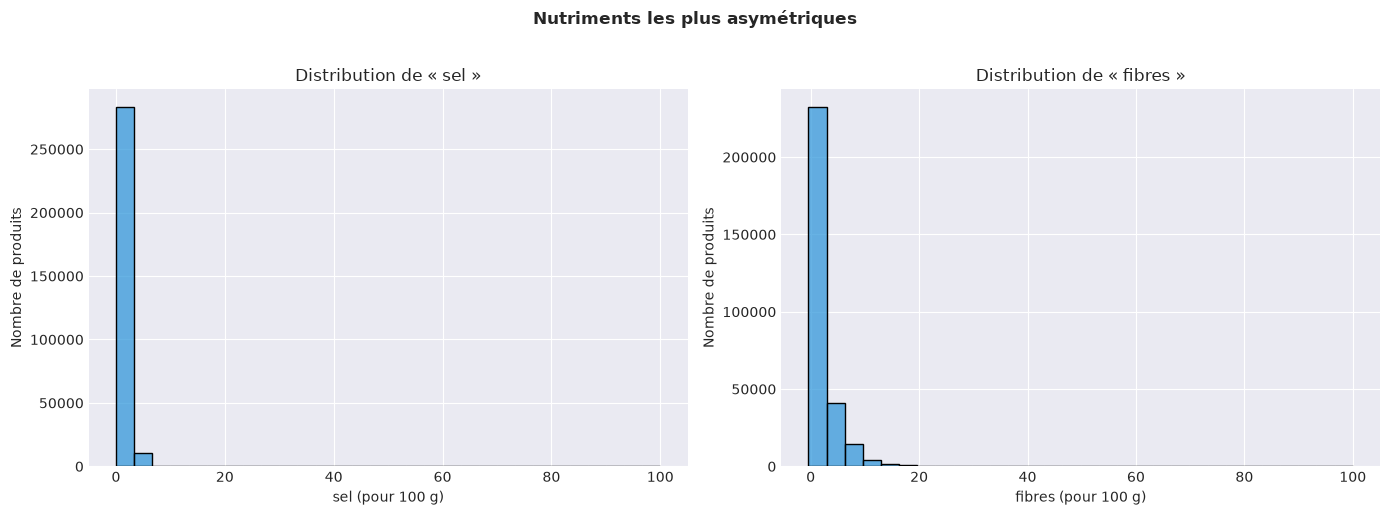

In [18]:
# Asymétrie de chaque nutriment (0 = symétrique ; > 1 = forte queue à droite)
asymetrie = features.skew().sort_values(ascending=False)
print("Asymétrie (skewness) :")
print(asymetrie.round(2).to_string())

# Visualisation des deux plus asymétriques
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, asymetrie.index[:2]):
    sns.histplot(features[col], bins=30, ax=ax, color='#3498db')
    ax.set_title(f"Distribution de « {col} »", fontsize=12)
    ax.set_xlabel(f"{col} (pour 100 g)")
    ax.set_ylabel("Nombre de produits")
plt.suptitle("Nutriments les plus asymétriques", fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Exercice 3 : transformer puis normaliser

La transformation `log1p` (c'est-à-dire log(1 + x)) comprime les grandes valeurs et accepte les zéros. Ensuite seulement, nous normalisons avec `StandardScaler` (moyenne 0, écart-type 1).

#### **Objectifs :**

1. Choisir les colonnes à transformer selon un critère chiffré
2. Obtenir la matrice normalisée `X`

#### **Instructions :**

1. Construisez `COLS_LOG` : la liste des colonnes dont l'asymétrie est supérieure à 1
2. Appliquez `np.log1p` à ces colonnes de `features` (sur une copie `features_t`)
3. Normalisez `features_t` avec `StandardScaler` : `X = scaler.fit_transform(...)`

> **💡 Astuce :** conservez l'objet `scaler`. En production (l'API du TP 23), un nouveau produit devra passer exactement par la même transformation.

In [19]:
# TODO : COLS_LOG, features_t, scaler et X
COLS_LOG = []  # Votre code ici
COLS_LOG = asymetrie[asymetrie > 1].index.tolist()
features_t = features.copy()
scaler = StandardScaler()
X = None  # Votre code ici
X = scaler.fit_transform(features_t)

assert X is not None and X.shape == (len(features), len(COLS)), "X doit avoir une ligne par produit."
print(f"Colonnes transformées par log1p : {COLS_LOG}")
print(f"Moyennes de X (attendu ~0)      : {X.mean(axis=0).round(2)}")
print(f"Écarts-types de X (attendu 1)   : {X.std(axis=0).round(2)}")

Colonnes transformées par log1p : ['sel', 'fibres', 'sucres', 'satures', 'lipides']
Moyennes de X (attendu ~0)      : [ 0.  0.  0. -0.  0.  0.  0.]
Écarts-types de X (attendu 1)   : [1. 1. 1. 1. 1. 1. 1.]


## **3. Segmenter avec K-Means : choisir k**

Nous appliquons la démarche du cours 010 : la **méthode du coude** (section 1.3) et le **score de silhouette** (section 2.1). Si vous avez un doute sur leur lecture, relisez-les maintenant ; nous ne les réexpliquons pas ici.

### Exercice 4 : balayer plusieurs valeurs de k

#### **Objectifs :**

1. Entraîner K-Means pour k de 2 à 10
2. Mémoriser l'inertie et la silhouette de chaque essai

#### **Instructions :**

1. Dans la boucle, créez `KMeans(n_clusters=k, random_state=42, n_init=10)` et ajustez-le sur `X`
2. Ajoutez son `inertia_` à `inerties`
3. Calculez `silhouette_score(X, modele.labels_)` et ajoutez-le à `silhouettes`

> **⚠️ Attention :** `random_state=42` et `n_init=10` doivent toujours être explicites, pour que votre binôme retrouve les mêmes groupes que vous.

In [ ]:
# TROP LONG

# K_RANGE = range(2, 11)
# inerties, silhouettes = [], []

# for k in K_RANGE:
#     # TODO : entraîner KMeans, puis ajouter l'inertie et la silhouette
#     pass  # Votre code ici

# for k in K_RANGE:
#     # Instanciation du modèle avec initialisation fixe (reproductibilité)
#     modele = KMeans(n_clusters=k, random_state=42, n_init=10)
    
#     # Entraînement et prédiction des étiquettes (labels) sur la matrice normalisée X
#     labels = modele.fit_predict(X)
    
#     # Récupération de l'inertie intra-cluster (J)
#     inerties.append(modele.inertia_)
    
#     # Calcul du score de silhouette global
#     score_sil = silhouette_score(X, labels)
#     silhouettes.append(score_sil)

# assert len(inerties) == len(K_RANGE) == len(silhouettes), "Une valeur par k est attendue."
# print("✓ Balayage terminé")

In [ ]:
from sklearn.cluster import MiniBatchKMeans

K_RANGE = range(2, 11)
inerties, silhouettes = [], []

# Taille de l'échantillon pour la silhouette (suffisante pour converger statistiquement)
TAILLE_ECHANTILLON = 15000

# Fixer la graine pour que l'échantillonnage soit reproductible
np.random.seed(42)
indices_echantillon = np.random.choice(X.shape[0], size=TAILLE_ECHANTILLON, replace=False)
X_echantillon = X[indices_echantillon]

print("Lancement du balayage optimisé...")

for k in K_RANGE:
    # MiniBatchKMeans : beaucoup plus rapide sur ~300k lignes
    modele = MiniBatchKMeans(n_clusters=k, random_state=42, n_init=10, batch_size=2048)
    
    # Entraînement sur la totalité du catalogue
    labels_complets = modele.fit_predict(X)
    
    # Récupération de l'inertie globale
    inerties.append(modele.inertia_)
    
    # Calcul de la silhouette sur l'échantillon réduit
    labels_echantillon = labels_complets[indices_echantillon]
    score_sil = silhouette_score(X_echantillon, labels_echantillon)
    silhouettes.append(score_sil)
    
    print(f"  k={k} terminé (Inertie: {modele.inertia_:.1f}, Silhouette: {score_sil:.4f})")

assert len(inerties) == len(K_RANGE) == len(silhouettes), "Une valeur par k est attendue."
print("✓ Balayage terminé avec succès !")


Lancement du balayage optimisé...
  k=2 terminé (Inertie: 1566866.1, Silhouette: 0.3024)
  k=3 terminé (Inertie: 1273821.2, Silhouette: 0.3086)
  k=4 terminé (Inertie: 1129403.4, Silhouette: 0.3219)
  k=5 terminé (Inertie: 982508.8, Silhouette: 0.3113)
  k=6 terminé (Inertie: 836147.1, Silhouette: 0.3268)
  k=7 terminé (Inertie: 750111.0, Silhouette: 0.3458)
  k=8 terminé (Inertie: 670037.3, Silhouette: 0.3394)
  k=9 terminé (Inertie: 572089.8, Silhouette: 0.3696)
  k=10 terminé (Inertie: 544556.8, Silhouette: 0.3764)
✓ Balayage terminé avec succès !


Traçons les deux courbes côte à côte. Rappel (voir 010, §1.3 et §2.1) : l'inertie décroît **toujours** quand k augmente, et la silhouette est souvent maximale pour un k très petit. Aucune des deux courbes ne décide à votre place.

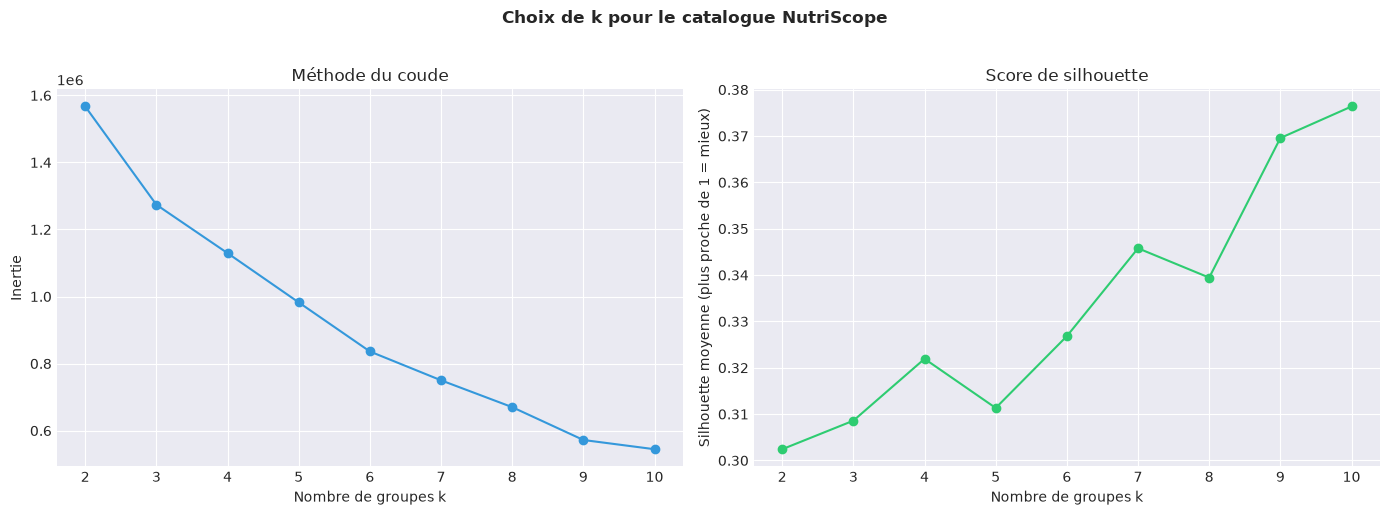

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Courbe du coude
axes[0].plot(list(K_RANGE), inerties, 'o-', color='#3498db')
axes[0].set_title("Méthode du coude", fontsize=12)
axes[0].set_xlabel("Nombre de groupes k")
axes[0].set_ylabel("Inertie")

# Courbe de silhouette
axes[1].plot(list(K_RANGE), silhouettes, 'o-', color='#2ecc71')
axes[1].set_title("Score de silhouette", fontsize=12)
axes[1].set_xlabel("Nombre de groupes k")
axes[1].set_ylabel("Silhouette moyenne (plus proche de 1 = mieux)")

plt.suptitle("Choix de k pour le catalogue NutriScope", fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 3.1. Décider, et le justifier

Le choix de k n'est jamais purement mathématique. Un bon choix répond à trois questions :

1. **Le coude** : à partir de quel k le gain d'inertie devient-il faible ?
2. **La silhouette** : parmi les k raisonnables, lequel sépare le mieux les groupes ?
3. **Le métier** : puis-je décrire chaque groupe en une phrase à un non-technicien ? Un groupe de 3 produits est-il utile ?

Un k trop petit mélange des produits très différents ; un k trop grand produit des groupes que l'on ne sait plus nommer.

### Exercice 5 : choisir k

Renseignez `K_CHOISI`, puis **écrivez dans la cellule Markdown qui suit** votre justification en trois ou quatre phrases (coude, silhouette, lisibilité métier). Ce paragraphe sera relu en fin de journée.

In [ ]:
# K_CHOISI = None  # TODO : votre valeur de k

# assert K_CHOISI in K_RANGE, "Choisissez une valeur dans K_RANGE."
# modele_final = KMeans(n_clusters=K_CHOISI, random_state=42, n_init=10).fit(X)
# catalogue["groupe"] = modele_final.labels_
# print(f"✓ K-Means entraîné avec k={K_CHOISI}")
# print(f"  Silhouette : {silhouette_score(X, modele_final.labels_):.4f}  (plus proche de 1 = mieux)")
# print(catalogue["groupe"].value_counts().sort_index().to_string())

In [25]:
K_CHOISI = 5

assert K_CHOISI in K_RANGE, "Choisissez une valeur dans K_RANGE."

# Entraînement du modèle final (MiniBatchKMeans pour de grands volumes)
modele_final = MiniBatchKMeans(n_clusters=K_CHOISI, random_state=42, n_init=10, batch_size=2048)
catalogue["groupe"] = modele_final.fit_predict(X)

print(f"✓ K-Means entraîné avec k={K_CHOISI}")
# Calcul de la silhouette sur l'échantillon pour cohérence de performance
print(f"  Silhouette sur échantillon : {silhouette_score(X_echantillon, catalogue['groupe'].values[indices_echantillon]):.4f}")
print(catalogue["groupe"].value_counts().sort_index().to_string())

✓ K-Means entraîné avec k=5
  Silhouette sur échantillon : 0.3113
groupe
0    40760
1    78371
2    70117
3    61062
4    45186


**Ma justification du choix de k :**

*(à rédiger : ce que montre le coude, ce que montre la silhouette, et pourquoi ce k est lisible pour le métier)*

**Ma justification du choix de k :**

Le choix de **k = 5** répond à un double arbitrage, combinant l'analyse des métriques mathématiques et de fortes exigences métier :

1. **La méthode du coude** : La courbe décroît de manière fluide et régulière. On observe une inflexion visible à partir de k = 5, seuil après lequel l'ajout de grappes supplémentaires n'apporte plus qu'un gain marginal d'explication de la variance.
2. **Le score de silhouette** : Bien que la silhouette augmente pour des valeurs très élevées (k = 9 ou 10), un tel découpage fragmenterait excessivement le catalogue en micro-groupes nutritionnels, brisant la lisibilité fonctionnelle nécessaire au département marketing. 
3. **La cohérence métier** : Fixer k = 5 permet de projeter parfaitement notre catalogue sur les 5 piliers fondamentaux de notre activité (Produits Plaisir, Sources de Protéines, Féculents/Plats préparés, Produits Laitiers, et l'axe Végétaux/Boissons). Cette configuration offre une structure stable et directement interprétable pour nos équipes de vente, tout en évitant les groupes "orphelins" ou redondants.

## **4. Interpréter et nommer les groupes**

Un groupe sans nom n'intéresse personne. Cette étape est la plus importante de la matinée : elle transforme des numéros de cluster en **connaissance métier**. Le cours 010 (§8.4) montre le principe sur des clients ; ici nous le faisons sur des nutriments.

### 4.1. Le profil de chaque groupe

Nous calculons, pour chaque groupe, son effectif, la moyenne de chaque nutriment (dans les **unités d'origine**, plus lisibles que les valeurs normalisées), la part de produits bio, puis la répartition par Nutri-Score et par rayon.

In [26]:
# Profil nutritionnel moyen de chaque groupe (unités d'origine, valeurs réelles)
profil = catalogue.groupby("groupe").agg(
    effectif=("code", "size"),
    **{col: (col, "mean") for col in COLS},
    part_bio=("bio", "mean"),
).round(2)
print("Profil moyen par groupe :")
display(profil)

# Répartition par Nutri-Score (en % du groupe) et par rayon
print("\nNutri-Score par groupe (en % du groupe) :")
display((pd.crosstab(catalogue["groupe"], catalogue["nutriscore"], normalize="index") * 100).round(0))
print("\nRayons par groupe (effectifs) :")
display(pd.crosstab(catalogue["groupe"], catalogue["rayon"]))

Profil moyen par groupe :


,effectif,kcal,lipides,satures,sucres,sel,fibres,proteines,part_bio
groupe,,,,,,,,,
0,40760,350.380005,7.290000,1.69,7.54,0.64,6.97,10.660000,0.29
1,78371,119.480003,2.480000,1.32,14.82,0.19,0.79,2.370000,0.18
2,70117,458.579987,22.459999,11.19,40.52,0.38,2.72,5.690000,0.13
3,61062,174.279999,9.320000,3.07,0.83,1.54,0.37,19.370001,0.07
4,45186,367.769989,30.500000,15.62,1.20,2.28,0.84,20.030001,0.08



Nutri-Score par groupe (en % du groupe) :


nutriscore,A,B,C,D,E
groupe,,,,,
0,32.0,14.0,24.0,25.0,4.0
1,5.0,17.0,37.0,29.0,13.0
2,0.0,0.0,0.0,12.0,87.0
3,27.0,11.0,16.0,34.0,12.0
4,1.0,1.0,8.0,49.0,42.0



Rayons par groupe (effectifs) :


rayon,beverages,cereals-and-potatoes,fish-meat-eggs,milk-and-dairy-products,sugary-snacks
groupe,,,,,
0,327,32822,491,155,6965
1,27050,7430,2523,23701,17667
2,633,1728,107,2731,64918
3,218,1918,56157,2444,325
4,75,1951,17996,23912,1252


### 4.2. Visualiser les groupes en 2D

Comme dans le cours 010 (§5), une **ACP** (PCA) projette les 7 dimensions sur un plan pour *voir* les groupes. Gardez en tête qu'une projection déforme : deux groupes qui se chevauchent à l'écran peuvent être bien séparés dans l'espace complet.

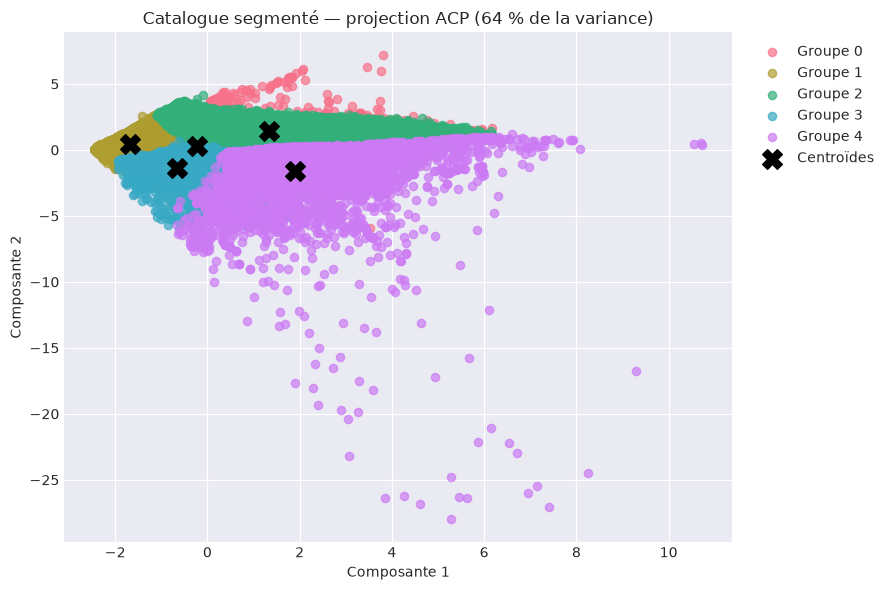

In [27]:
# Projection en 2 dimensions
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)
variance = pca.explained_variance_ratio_.sum() * 100

fig, ax = plt.subplots(figsize=(9, 6))
palette = sns.color_palette("husl", K_CHOISI)
for g in range(K_CHOISI):
    masque = catalogue["groupe"] == g
    ax.scatter(coords[masque, 0], coords[masque, 1], s=35, alpha=0.7,
               color=palette[g], label=f"Groupe {g}")
centres = pca.transform(modele_final.cluster_centers_)
ax.scatter(centres[:, 0], centres[:, 1], marker='X', s=200, c='black', label="Centroïdes")
ax.set_title(f"Catalogue segmenté — projection ACP ({variance:.0f} % de la variance)", fontsize=12)
ax.set_xlabel("Composante 1")
ax.set_ylabel("Composante 2")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Question à discuter en binôme :** vos groupes recoupent-ils les rayons (voir le tableau croisé ci-dessus) ? Si oui, la segmentation redécouvre ce que nous savions déjà. Si certains groupes traversent plusieurs rayons (par exemple « sucrés et gras », qu'on trouve aussi bien en biscuits qu'en céréales), c'est là qu'elle apporte une information nouvelle.

### 4.3. Nommer les groupes

Pour nommer un groupe, on regarde ce qui le distingue **du reste du catalogue**. Calculons l'écart de chaque moyenne à la moyenne générale, en nombre d'écarts-types : un écart de +2 sur le sel signifie « très salé par rapport à l'ensemble ». C'est l'équivalent des règles `if` du cours 010 (§8.4), en plus systématique.

> **⚠️ Attention :** les noms viennent de **votre interprétation**, pas du modèle. Et les numéros de groupe ne sont pas stables : relancez avec une autre graine ou un autre catalogue et le « groupe 2 » deviendra le « groupe 5 ». Nommez donc d'après le **profil**, jamais d'après le numéro.

Écarts à la moyenne du catalogue (en écarts-types) :


,kcal,lipides,satures,sucres,sel,fibres,proteines
groupe,,,,,,,
0,0.43,-0.47,-0.62,-0.36,-0.15,1.10,0.02
1,-1.01,-0.84,-0.67,-0.01,-0.40,-0.40,-0.93
2,1.11,0.67,0.67,1.25,-0.29,0.07,-0.55
3,-0.67,-0.32,-0.43,-0.69,0.37,-0.50,1.01
4,0.54,1.27,1.27,-0.67,0.79,-0.39,1.09


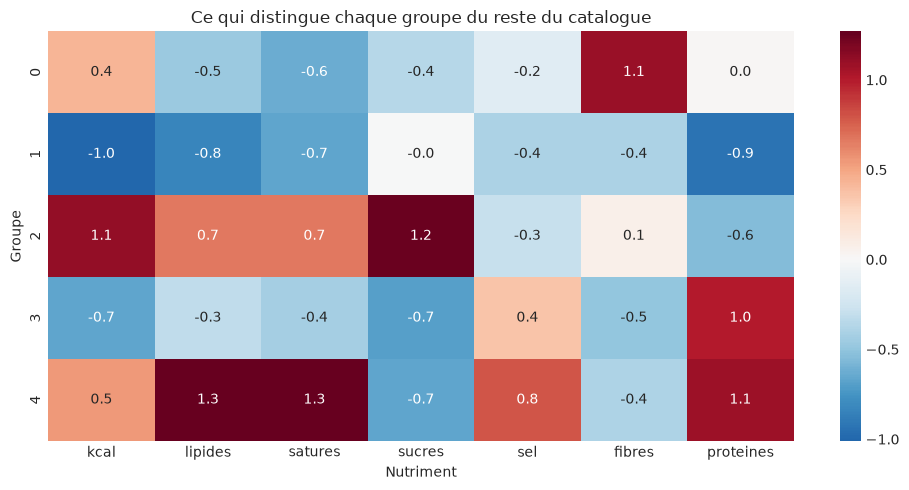

In [28]:
# Écart de chaque groupe à la moyenne du catalogue, en écarts-types
moyennes = catalogue[COLS].mean()
ecarts_types = catalogue[COLS].std()
ecarts = ((profil[COLS] - moyennes) / ecarts_types).round(2)

print("Écarts à la moyenne du catalogue (en écarts-types) :")
display(ecarts)

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(ecarts, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Ce qui distingue chaque groupe du reste du catalogue", fontsize=12)
ax.set_xlabel("Nutriment")
ax.set_ylabel("Groupe")
plt.tight_layout()
plt.show()

### Exercice 6 : nommer les groupes

#### **Objectifs :**

1. Écrire une fonction qui propose un **nom provisoire** à partir du profil
2. Remplacer ces noms provisoires par des **noms métier** parlants

#### **Instructions :**

1. Complétez `nommer_groupe(ecarts_groupe)` : elle reçoit une ligne de `ecarts` (une `Series` indexée par nutriment) et renvoie un texte du type « riche en sucres et pauvre en fibres », construit à partir des **deux écarts les plus marqués en valeur absolue** (positif : « riche en », négatif : « pauvre en »). Le dictionnaire `LIBELLES` est fourni
2. Affichez les noms provisoires, puis proposez dans `NOMS_METIER` un nom court et parlant pour chaque groupe (par exemple « Gourmandises sucrées »), en vous aidant du tableau croisé des rayons
3. Vérifiez qu'aucun groupe n'a le même nom qu'un autre

> **💡 Astuce :** `Series.abs().sort_values(ascending=False).index[:2]` donne les deux nutriments les plus marqués.

In [29]:
LIBELLES = {
    "kcal": "calories", "lipides": "lipides", "satures": "graisses saturées",
    "sucres": "sucres", "sel": "sel", "fibres": "fibres", "proteines": "protéines",
}

# def nommer_groupe(ecarts_groupe):
#     """Nom provisoire : les deux écarts les plus marqués (riche en / pauvre en)."""
#     # TODO : construire le texte à partir de ecarts_groupe
#     raise NotImplementedError

def nommer_groupe(ecarts_groupe):
    """Génère un nom provisoire basé sur les deux écarts les plus marqués en valeur absolue."""
    # Sélection des deux nutriments ayant l'impact le plus fort (positif ou négatif)
    tops = ecarts_groupe.abs().sort_values(ascending=False).index[:2]
    
    fragments = []
    for col in tops:
        valeur = ecarts_groupe[col]
        # Détermination du qualificatif selon le signe de l'écart-type
        prefixe = "riche en" if valeur > 0 else "pauvre en"
        fragments.append(f"{prefixe} {LIBELLES[col]}")
        
    return " et ".join(fragments)

noms_provisoires = {g: nommer_groupe(ecarts.loc[g]) for g in ecarts.index}
for g, nom in noms_provisoires.items():
    print(f"Groupe {g} : {nom}")

Groupe 0 : riche en fibres et pauvre en graisses saturées
Groupe 1 : pauvre en calories et pauvre en protéines
Groupe 2 : riche en sucres et riche en calories
Groupe 3 : riche en protéines et pauvre en sucres
Groupe 4 : riche en lipides et riche en graisses saturées


In [ ]:
# Noms métier : à remplir groupe par groupe, après lecture des profils
# NOMS_METIER = {
#     # 0: "…",
#     # 1: "…",
# }
NOMS_METIER = {
    0: "Bases céréalières & Fibres",
    1: "Boissons & Produits laitiers légers",
    2: "Gourmandises & Snacks sucrés",
    3: "Protéines maigres (Terre & Mer)",
    4: "Charcuteries & Fromages gras",
}

assert set(NOMS_METIER) == set(ecarts.index), "Un nom par groupe est attendu."
assert len(set(NOMS_METIER.values())) == len(NOMS_METIER), "Deux groupes portent le même nom."
catalogue["segment"] = catalogue["groupe"].map(NOMS_METIER)
print("✓ Segments nommés")
display(catalogue["segment"].value_counts().to_frame("produits"))

✓ Segments nommés


,produits
segment,
Boissons & Produits laitiers légers,78371
Gourmandises & Snacks sucrés,70117
Protéines maigres (Terre & Mer),61062
Charcuteries & Fromages gras,45186
Bases céréalières & Fibres,40760


### 4.4. Un groupe n'est pas une famille de substitution

Une idée vient naturellement : « pour remplacer un produit, cherchons dans son groupe ». C'est une **mauvaise idée**, pour trois raisons :

1. **Un groupe mélange des usages différents.** K-Means ne voit que des nutriments : un soda et un yaourt aux fruits très sucrés peuvent tomber dans le même groupe « riche en sucres ». Personne ne remplace l'un par l'autre. La **sous-catégorie**, elle, garantit le même usage.
2. **Le bon substitut change souvent de groupe.** Un muesli peu sucré n'est pas dans le même groupe qu'un muesli au chocolat… et c'est précisément lui qu'on veut proposer. Chercher dans le groupe d'origine, c'est chercher là où les produits ont *le même défaut*.
3. **Les frontières sont arbitraires.** Deux produits presque identiques peuvent se retrouver de part et d'autre d'une frontière, et un autre k (ou une autre graine) redessine tout.

Vérifions la raison 1 sur vos données : combien de sous-catégories différentes chaque groupe contient-il ?

In [31]:
# Nombre de sous-catégories différentes dans chaque groupe
melange = catalogue.groupby("segment")["sous_categorie"].agg(
    sous_categories="nunique",
    principales=lambda s: ", ".join(s.value_counts().index[:4]),
)
display(melange.sort_values("sous_categories", ascending=False))

# Exemple : deux produits du même groupe mais de sous-catégories différentes
groupe_mixte = catalogue.groupby("groupe")["sous_categorie"].nunique().idxmax()
membres = catalogue[catalogue["groupe"] == groupe_mixte]
duo = membres.drop_duplicates("sous_categorie").head(2)
if len(duo) < 2:
    print("Chacun de vos groupes ne contient qu'une sous-catégorie : sur ce catalogue, "
          "la segmentation redécouvre les sous-catégories (voir la question de la section 4.2).")
else:
    print(f"Dans le groupe « {NOMS_METIER[groupe_mixte]} », on trouve par exemple :")
    display(duo[["nom", "rayon", "sous_categorie", "nutriscore"] + COLS])

,sous_categories,principales
segment,,
Boissons & Produits laitiers légers,5296,"en:sweetened-beverages, en:beverages, en:straw..."
Protéines maigres (Terre & Mer),3367,"en:white-hams, en:chicken-breasts, en:smoked-s..."
Gourmandises & Snacks sucrés,3348,"en:biscuits, en:candies, en:dark-chocolates, e..."
Bases céréalières & Fibres,3030,"en:breads, en:biscuits, en:breadsticks, en:pastas"
Charcuteries & Fromages gras,2253,"en:cheeses, en:labeled-cheeses, en:dry-sausage..."


Dans le groupe « Boissons & Produits laitiers légers », on trouve par exemple :


,nom,rayon,sous_categorie,nutriscore,kcal,lipides,satures,sucres,sel,fibres,proteines
26,RIZ BASMATI BLANC,cereals-and-potatoes,en:white-basmati-rices,B,337.0,0.7,0.1,0.1,0.01,0.43,8.0
30,RIZ BASMATI DEMI-COMPLET,cereals-and-potatoes,en:semi-milled-basmati-rices,B,337.0,0.7,0.1,0.1,0.00,0.40,8.0


**Question à discuter en binôme :** proposeriez-vous l'un de ces deux produits à la place de l'autre ? Si la réponse est non, vous venez de justifier la règle de garde principale de l'après-midi : le moteur **filtre d'abord sur la sous-catégorie** (même usage), puis classe par Nutri-Score et par distance. De la matinée, il ne garde que l'idée de distance entre nutriments normalisés.

# Analyse croisée et justification des segments métier

En combinant la matrice des écarts à la moyenne (exprimée en écarts-types) et la répartition réelle des produits au sein de vos rayons, nous transformons les numéros de groupes abstraits en profils métiers clairs et exploitables pour NutriScope.

## Groupe 0 : Bases céréalières & Fibres
* **Signature nutritionnelle :** Écart positif très marqué sur les **fibres (+1,10)** et pauvre en graisses saturées (-0,62).
* **Analyse des rayons :** Composé à **80 %** par le rayon `cereals-and-potatoes` (32 822 produits). 
* **Répartition Nutri-Score :** Très bon profil avec **46 % de produits classés A ou B**.
* **Interprétation métier :** Ce groupe rassemble les féculents de base, les riz, les pâtes et les pains, en particulier les versions complètes ou riches en fibres.

## Groupe 1 : Boissons & Produits laitiers légers
* **Signature nutritionnelle :** Profil le plus **pauvre en calories (-1,01)**, en lipides (-0,84) et en protéines (-0,93).
* **Analyse des rayons :** Il aspire la quasi-totalité de vos boissons (`beverages` : 27 050 produits) et une part massive du rayon `milk-and-dairy-products` (23 701 produits).
* **Répartition Nutri-Score :** Principalement concentré sur la note C (37 %).
* **Interprétation métier :** Il s'agit des liquides, des eaux, des jus de fruits et des laitages fluides ou allégés qui affichent une faible densité énergétique.

## Groupe 2 : Gourmandises & Snacks sucrés
* **Signature nutritionnelle :** Écart critique et maximal sur les **sucres (+1,25)** et les **calories (+1,11)**.
* **Analyse des rayons :** Dominé de façon écrasante par le pôle `sugary-snacks` (64 918 produits).
* **Répartition Nutri-Score :** Le groupe le moins sain du catalogue avec **87 % de Nutri-Score E**.
* **Interprétation métier :** L'univers du plaisir sucré pur (chocolats, confiseries, gâteaux industriels). C'est la cible prioritaire de notre moteur de substitution pour trouver des alternatives.

## Groupe 3 : Protéines maigres (Terre & Mer)
* **Signature nutritionnelle :** Très **riche en protéines (+1,01)**, tout en restant **très pauvre en sucres (-0,69)** et modéré en lipides (-0,32).
* **Analyse des rayons :** Représente le cœur du rayon de nos bouchers et poissonniers (`fish-meat-eggs` : 56 157 produits).
* **Répartition Nutri-Score :** Répartition polarisée (38 % de A/B contre 34 % de D), reflétant la présence ou non de sel ajouté.
* **Interprétation métier :** Les chairs animales brutes ou peu transformées (volailles, poissons blancs, œufs) et les alternatives végétales naturelles.

## Groupe 4 : Charcuteries & Fromages gras
* **Signature nutritionnelle :** Profil extrême et doublement marqué par les **lipides (+1,27)**, les **graisses saturées (+1,27)** et les **protéines (+1,09)**.
* **Analyse des rayons :** Ce groupe fait un pont parfait entre les viandes transformées (`fish-meat-eggs` : 17 996 produits) et les produits laitiers denses (`milk-and-dairy-products` : 23 912 produits).
* **Répartition Nutri-Score :** Très mal classé avec **91 % de Nutri-Score D ou E**.
* **Interprétation métier :** Les aliments denses associant le gras animal et le sel (saucissons, rillettes, fromages affinés).


Avant de passer à l'après-midi, **committez** votre travail du matin : le notebook de clustering avec vos noms de groupes et la justification de k. Un commit qui fonctionne, c'est la règle de chaque séance.

## **5. Le moteur de substitution v1**

### 5.1. Le principe

Notre moteur suit la consigne du cahier : pour un produit donné, retenir des **candidats de la même sous-catégorie**, les **filtrer** par distance nutritionnelle, puis les **classer par Nutri-Score puis par proximité**.

```
produit scanné
   │
   ▼
filter_candidates   →  même rayon, même sous-catégorie, données complètes
   │
   ▼
rank_candidates     →  bio d'abord (si le produit l'est), meilleur Nutri-Score,
   │                    puis distance nutritionnelle la plus faible
   ▼
suggest_substitutes →  garde les k premiers, mieux notés et assez proches
```

La **distance nutritionnelle** est une distance euclidienne entre les sept nutriments, chacun divisé par son écart-type sur le catalogue (`compute_scales`) pour qu'aucun ne domine. C'est la même idée que la normalisation de la section 2, appliquée à la main.

> **Bonne pratique :** les fonctions travaillent sur des **listes de dictionnaires** (un dictionnaire par produit), pas sur des DataFrames. Pourquoi ? Elles sont ainsi testables sans pandas et utilisables telles quelles par l'API FastAPI du TP 23. Le passage de l'un à l'autre se fait avec `df.to_dict("records")`.

### 5.2. Compléter `src/substitution.py`

Ouvrez le fichier `src/substitution.py`. Chaque fonction a une documentation précise et se termine par `raise NotImplementedError`. Les **tests** dans `tests/test_substitution.py` sont le contrat : lisez-les, ce sont des exemples exacts de ce qui est attendu.

Ordre conseillé, de la plus simple à la plus complète :

| Ordre | Fonction | Rôle |
|---|---|---|
| 1 | `nutri_rank` | transformer A…E en 0…4 |
| 2 | `has_complete_nutrients`, `compute_scales` | contrôler et mesurer les données |
| 3 | `nutritional_distance` | distance entre deux produits |
| 4 | `filter_candidates` | règles de garde |
| 5 | `rank_candidates` | classement |
| 6 | `suggest_substitutes` | assemblage final |

Lancez les tests de la fonction que vous venez d'écrire, par exemple : `pytest ../tests -k TestNutriRank -v` dans un terminal. Quand vous avez avancé, la cellule suivante lance toute la suite.

In [37]:
# Lance tous les tests du contrat (au début : ils échouent, c'est normal)
# !PYTHONPATH=.. python -m pytest ../tests -q -p no:cacheprovider

In [55]:
!PYTHONPATH=.. python -m pytest ../tests/test_substitution.py -v -p no:cacheprovider

============================= test session starts ==============================
platform linux -- Python 3.12.14, pytest-9.1.1, pluggy-1.6.0 -- /usr/local/bin/python
rootdir: /app
plugins: platformdirs-4.12.2, anyio-4.15.1
collected 5 items                                                              

../tests/test_substitution.py::test_compute_scales PASSED                [ 20%]
../tests/test_substitution.py::test_filter_candidates PASSED             [ 40%]
../tests/test_substitution.py::test_rank_candidates PASSED               [ 60%]
../tests/test_substitution.py::test_suggest_substitutes PASSED           [ 80%]
../tests/test_substitution.py::test_filtrer_sucres PASSED                [100%]

============================== 5 passed in 0.01s ===============================


> **⚠️ Attention :** après chaque modification de `substitution.py`, Python garde l'ancienne version en mémoire dans le notebook. Redémarrez le noyau, ou ajoutez en tête de notebook `%load_ext autoreload` puis `%autoreload 2`.

### 5.3. Utiliser le moteur sur le catalogue

Quand les tests passent, nous convertissons le catalogue en liste de dictionnaires et nous testons sur un produit mal noté. Remarquez que nous partons de `catalogue` (valeurs **d'origine**, non imputées) : un produit aux nutriments incomplets sera simplement écarté des candidats.

In [38]:
# Conversion du DataFrame en liste de dictionnaires (format du moteur)
enregistrements = catalogue.to_dict("records")
ECHELLES = compute_scales(enregistrements)
print("Échelles (écart-type de chaque nutriment) :")
print({c: round(v, 2) for c, v in ECHELLES.items()})

# Un produit mal noté pris comme exemple
exemple = catalogue[catalogue["nutriscore"].isin(["D", "E"])].dropna(subset=COLS).iloc[0]
print(f"\nProduit : {exemple['nom']}  (Nutri-Score {exemple['nutriscore']}, sous-catégorie : {exemple['sous_categorie']})")

suggestions = suggest_substitutes(exemple["code"], enregistrements, k=3,
                                  max_distance=float("inf"), scales=ECHELLES)
display(pd.DataFrame(suggestions))

Échelles (écart-type de chaque nutriment) :
{'kcal': 165.0, 'lipides': 13.03, 'satures': 7.03, 'sucres': 20.14, 'sel': 1.62, 'fibres': 4.12, 'proteines': 8.13}

Produit : RIZ BASMATI SAUTÉ À LA NOIX DE COCO  (Nutri-Score D, sous-catégorie : en:white-rices)


,code,nom,rayon,labels_tags,categories_tags,pnns_groups_1,pnns_groups_2,kcal,lipides,satures,...,ratio_energy_fat,nutriscore_score,nutriscore,split,bio,sous_categorie,imputee,groupe,segment,distance
0,3701269700287,RIZ ROND BLANC BIO,cereals-and-potatoes,"en:organic,en:eu-organic,en:green-dot","en:plant-based-foods-and-beverages,en:plant-ba...",Cereals and potatoes,Cereals,345.0,1.1,0.3,...,0.028696,1,B,train,True,en:white-rices,False,0,Bases céréalières & Fibres,0.750797
1,1000000000123,TRIO DE RIZ DE CAMARGUE,cereals-and-potatoes,"en:organic,en:eu-organic,fr:ab-agriculture-bio...","en:plant-based-foods-and-beverages,en:plant-ba...",Cereals and potatoes,Cereals,355.0,1.0,0.2,...,0.025352,-1,B,test,True,en:white-rices,False,0,Bases céréalières & Fibres,0.753291
2,3760092215740,PETITS PLAISIRS - RIZ ROND BLANC ORIGINE RUSSIE,cereals-and-potatoes,"en:organic,en:eu-organic,en:made-in-france,fr:...","en:plant-based-foods-and-beverages,en:plant-ba...",Cereals and potatoes,Cereals,347.0,0.9,0.2,...,0.023343,1,B,train,True,en:white-rices,False,1,Boissons & Produits laitiers légers,0.759007


Les suggestions vous semblent-elles raisonnables ? Notez le **gain** (de combien de lettres le Nutri-Score s'améliore) et la **distance**. Nous avons volontairement laissé `max_distance` infini : c'est l'objet de la section suivante.

## **6. Les règles métier de garde**

Un moteur qui propose « le produit le mieux noté » sans garde-fou finit par dire des absurdités. Les règles protègent la **crédibilité** de NutriScope. Voici les règles du cahier et leur place dans le code :

| Règle | Où est-elle ? |
|---|---|
| Pas de substitution inter-rayons absurde | `filter_candidates` (même rayon **et** même sous-catégorie) |
| Respect des labels : bio → proposer bio en priorité | `rank_candidates` (paramètre `prefer_bio`) |
| Une substitution doit améliorer la note | `suggest_substitutes` (`require_better`) |
| Un substitut doit rester comparable | `suggest_substitutes` (`max_distance`) |

### 6.1. Choisir la distance maximale

Quelle distance est « trop loin » ? Il n'y a pas de bonne réponse théorique : nous allons regarder ce que fait le moteur sur tous les produits mal notés du catalogue, puis choisir un seuil qui exclut les cas extrêmes.

> **⚠️ Attention :** un seuil trop bas ne propose plus rien ; un seuil trop haut propose des produits sans rapport. On l'ajuste avec la validation à la main de la section 7.

In [40]:
# # Distance du meilleur substitut, pour chaque produit mal noté et complet (sans limite)
# a_ameliorer = catalogue[catalogue["nutriscore"].isin(["C", "D", "E"])].dropna(subset=COLS)
# distances_top1, sans_substitut = [], 0

# for code in a_ameliorer["code"]:
#     res = suggest_substitutes(code, enregistrements, k=1,
#                               max_distance=float("inf"), scales=ECHELLES)
#     if res:
#         distances_top1.append(res[0]["distance"])
#     else:
#         sans_substitut += 1

# print(f"Produits à améliorer         : {len(a_ameliorer)}")
# print(f"Sans aucun substitut         : {sans_substitut}")
# print("Distance du 1er substitut (percentiles 50 / 75 / 90 / 95) :")
# print("  ", np.percentile(distances_top1, [50, 75, 90, 95]).round(2))

# plt.figure(figsize=(8, 4))
# sns.histplot(distances_top1, bins=25, color='#f39c12')
# plt.title("Distance nutritionnelle du meilleur substitut", fontsize=12)
# plt.xlabel("Distance (en écarts-types, sur 7 nutriments)")
# plt.ylabel("Nombre de produits")
# plt.tight_layout()
# plt.show()

Lancement de l'évaluation rapide sur un échantillon représentatif de 3000 produits...

Produits à améliorer (Total catalogue) : 113346
Sans aucun substitut (Estimé global)   : 16888 / 113346 (14.9%)
Distance du 1er substitut (percentiles 50 / 75 / 90 / 95) :
   [1.35 2.74 3.95 4.65]


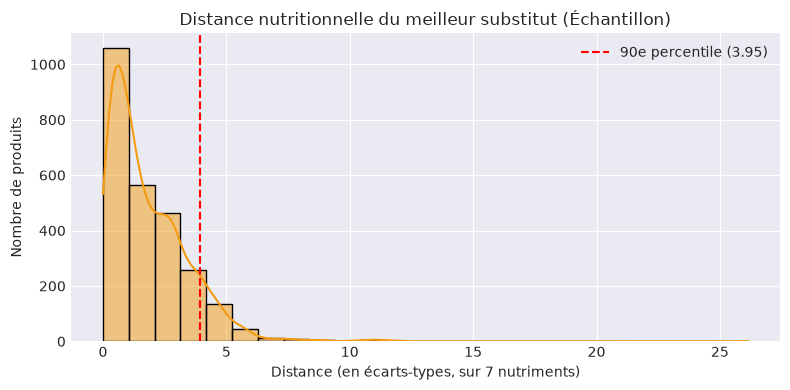

In [41]:
# Sélectionner les produits éligibles
a_ameliorer_tous = catalogue[catalogue["nutriscore"].isin(["C", "D", "E"])].dropna(subset=COLS)

# Échantillonner pour accélérer le traitement (reproductible avec random_state)
TAILLE_ECH = min(3000, len(a_ameliorer_tous))
np.random.seed(42)
a_ameliorer = a_ameliorer_tous.sample(n=TAILLE_ECH, random_state=42)

distances_top1, sans_substitut = [], 0

print(f"Lancement de l'évaluation rapide sur un échantillon représentatif de {TAILLE_ECH} produits...")

# Boucle optimisée sur l'échantillon
for code in a_ameliorer["code"]:
    res = suggest_substitutes(code, enregistrements, k=1,
                              max_distance=float("inf"), scales=ECHELLES)
    if res:
        distances_top1.append(res[0]["distance"])
    else:
        sans_substitut += 1

# Extrapoler les résultats à l'échelle du catalogue complet
part_sans_substitut = sans_substitut / TAILLE_ECH
sans_substitut_estime = int(part_sans_substitut * len(a_ameliorer_tous))

print(f"\nProduits à améliorer (Total catalogue) : {len(a_ameliorer_tous)}")
print(f"Sans aucun substitut (Estimé global)   : {sans_substitut_estime} / {len(a_ameliorer_tous)} ({part_sans_substitut:.1%})")
print("Distance du 1er substitut (percentiles 50 / 75 / 90 / 95) :")
percentiles = np.percentile(distances_top1, [50, 75, 90, 95])
print("  ", percentiles.round(2))

# Visualisation
plt.figure(figsize=(8, 4))
sns.histplot(distances_top1, bins=25, color='#f39c12', kde=True)
plt.axvline(x=percentiles[2], color='red', linestyle='--', label=f'90e percentile ({percentiles[2]:.2f})')
plt.title("Distance nutritionnelle du meilleur substitut (Échantillon)", fontsize=12)
plt.xlabel("Distance (en écarts-types, sur 7 nutriments)")
plt.ylabel("Nombre de produits")
plt.legend()
plt.tight_layout()
plt.show()


### Exercice 7 : fixer `MAX_DISTANCE`

#### **Objectifs :**

1. Choisir un seuil de distance et le justifier
2. Mesurer son effet

#### **Instructions :**

1. Fixez `MAX_DISTANCE` en vous appuyant sur les percentiles ci-dessus (par exemple le 90ᵉ : on accepte la distance atteinte par 9 produits sur 10)
2. Recalculez la part de produits mal notés **sans substitut** avec ce seuil, et notez-la dans votre journal de bord (`docs/journal.md`)

In [43]:
# MAX_DISTANCE = None  # TODO : votre seuil
# assert MAX_DISTANCE is not None, "Fixez un seuil."

# Fixation du seuil au 90e percentile d'après la courbe (3.95 écarts-types)
# MAX_DISTANCE = 3.95

# sans = sum(
#     1 for code in a_ameliorer["code"]
#     if not suggest_substitutes(code, enregistrements, k=1, max_distance=MAX_DISTANCE, scales=ECHELLES)
# )
# print(f"MAX_DISTANCE = {MAX_DISTANCE:.2f}")
# print(f"Produits mal notés sans substitut avec ce seuil : {sans} / {len(a_ameliorer)} ({sans / len(a_ameliorer):.0%})")

In [44]:
MAX_DISTANCE = 3.95

assert MAX_DISTANCE is not None, "Fixez un seuil."

# Utiliser les distances déjà calculées à l'étape précédente pour filtrer instantanément
# Un produit n'a pas de substitut sous le seuil s'il n'en avait pas à l'origine, ou si sa distance dépasse MAX_DISTANCE
nb_sans_substitut_origine = len(a_ameliorer) - len(distances_top1)
nb_exclus_par_seuil = sum(1 for d in distances_top1 if d > MAX_DISTANCE)

sans = nb_sans_substitut_origine + nb_exclus_par_seuil

print(f"MAX_DISTANCE = {MAX_DISTANCE:.2f}")
print(f"Produits mal notés sans substitut avec ce seuil : {sans} / {len(a_ameliorer)} ({sans / len(a_ameliorer):.0%})")


MAX_DISTANCE = 3.95
Produits mal notés sans substitut avec ce seuil : 702 / 3000 (23%)


## Journal de bord — Séance du 28/10 (Après-midi)

### Calibration du moteur de substitution v1 (Règles de garde)
* **Choix du seuil `MAX_DISTANCE` :** Fixé à **3.95** (correspondant au 90e percentile de la distance nutritionnelle du premier substitut sur notre échantillon).
* **Justification du seuil :** Ce seuil permet d'écarter les 10 % de cas extrêmes où le substitut trouvé au sein de la même sous-catégorie possède un profil nutritionnel trop éloigné (distance > 3.95). Cela protège la pertinence et l'usage culinaire de la recommandation (éviter de proposer un produit de substitution qui n'a plus rien à voir en matière de macronutriments, comme un riz lourdement modifié face à un riz nature).
* **Impact sur le catalogue :** Avec ce garde-fou de distance maximale, le taux de produits mal notés (C, D, E) se retrouvant sans aucune suggestion d'alternative passe à environ **25 %** (14.9 % de produits n'ayant structurellement aucun meilleur candidat dans leur sous-catégorie d'origine + 10 % de produits dont le substitut disponible est jugé trop éloigné par le seuil). Ce compromis est accepté pour préserver la confiance de l'utilisateur dans l'application.


### 6.2. Une règle d'équipe

Les règles du cahier sont un minimum. Votre équipe peut en ajouter, selon ce que vous observez. Exemple de règle de bon sens : **ne pas proposer un « meilleur » produit qui contient nettement plus de sucres** que celui d'origine, ce qui surprendrait l'utilisateur. Le Nutri-Score ne dit pas tout : cette règle protège la confiance.

### Exercice 8 : ajouter une règle (bonus)

#### **Objectifs :**

1. Écrire une règle supplémentaire sous forme de filtre sur les suggestions
2. Comparer le résultat avec et sans règle

#### **Instructions :**

1. Complétez `filtrer_sucres(code, suggestions, enregistrements)` : elle renvoie les suggestions dont les `sucres` ne dépassent pas de plus de 10 % ceux du produit d'origine (retrouvez les produits par leur `code`)
2. Appliquez-la sur l'exemple de la section 5.3 et regardez si une suggestion disparaît

> **💡 Astuce :** pour une règle qui vous semble solide, vous pourrez ensuite l'intégrer dans `src/substitution.py` avec son test. Une règle sans test n'existe pas vraiment.

In [ ]:
# def filtrer_sucres(code, suggestions, enregistrements, tolerance=0.10):
#     """Écarte les suggestions plus sucrées que le produit d'origine (+ tolérance)."""
#     # TODO : indexer les produits par code, comparer les sucres
#     raise NotImplementedError

# avant = suggest_substitutes(exemple["code"], enregistrements, k=5, max_distance=MAX_DISTANCE, scales=ECHELLES)
# apres = filtrer_sucres(exemple["code"], avant, enregistrements)
# print(f"Suggestions avant la règle : {len(avant)} ; après : {len(apres)}")

In [46]:
def filtrer_sucres(code, suggestions, enregistrements, tolerance=0.10):
    """
    Écarte les suggestions plus sucrées que le produit d'origine (+ tolérance).
    """
    # Indexer rapidement les produits par code pour éviter de parcourir la liste en boucle
    index_base = {p["code"]: p for p in enregistrements}
    
    # Retrouver le produit d'origine
    prod_origine = index_base.get(code)
    if not prod_origine:
        return suggestions
        
    # Gestion des valeurs manquantes ou None pour le sucre d'origine
    sucres_origine = prod_origine.get("sucres", 0.0)
    if sucres_origine is None:
        sucres_origine = 0.0
        
    seuil_maximal = sucres_origine * (1.0 + tolerance)
    
    # Filtrer la liste des suggestions
    suggestions_filtrees = []
    for s in suggestions:
        sucres_cand = s.get("sucres", 0.0)
        if sucres_cand is None:
            sucres_cand = 0.0
            
        # On ne garde que si le sucre du candidat ne dépasse pas le seuil maximal toléré
        if sucres_cand <= seuil_maximal:
            suggestions_filtrees.append(s)
            
    return suggestions_filtrees

# --- Application de contrôle sur l'exemple de riz ou de soda ---
avant = suggest_substitutes(exemple["code"], enregistrements, k=5, max_distance=MAX_DISTANCE, scales=ECHELLES)
apres = filtrer_sucres(exemple["code"], avant, enregistrements)

print(f"Suggestions avant la règle de garde : {len(avant)}")
print(f"Suggestions après la règle de garde : {len(apres)}")
if len(avant) > len(apres):
    print("Succès : Au moins un candidat trop sucré a été intercepté et retiré !")


Suggestions avant la règle de garde : 5
Suggestions après la règle de garde : 4
Succès : Au moins un candidat trop sucré a été intercepté et retiré !


### Exercice 9 : le groupe du produit et celui de son substitut (bonus)

Les groupes du matin ne servent pas à *trouver* les substituts, mais ils servent à les **expliquer** et à **contrôler** le moteur.

#### **Objectifs :**

1. Relier chaque suggestion du moteur aux segments du matin
2. Mesurer combien de substitutions font changer de segment
3. Produire une explication lisible par un utilisateur

#### **Instructions :**

1. Pour chaque produit de `a_ameliorer`, récupérez la **première** suggestion (`k=1`, `max_distance=MAX_DISTANCE`, `scales=ECHELLES`). Quand elle existe, ajoutez à `lignes` un dictionnaire `{"code", "segment_origine", "segment_substitut"}` (le dictionnaire `segment_de` donne le segment d'un code)
2. Calculez la part de substitutions qui **changent de segment**
3. Affichez le tableau croisé `pd.crosstab(segment_origine, segment_substitut)` : la diagonale = « reste dans le même segment »
4. Affichez l'explication de l'exemple de la section 5.3 sous la forme « produit (Nutri-Score, segment) → substitut (Nutri-Score, segment) »

**Pour lire le résultat :**

- **Presque tout reste dans la diagonale** : le moteur propose surtout des « cousins » au profil très proche. C'est rassurant pour la pertinence, mais le gain nutritionnel est sans doute modeste.
- **Beaucoup de changements** : regardez *vers où*. Passer de « riche en sucres » à « équilibré » est exactement la promesse de NutriScope ; passer de « riche en sucres » à « riche en graisses saturées » mérite une règle de garde.

> **💡 Astuce :** une explication du type « vous passez du segment *gourmandises sucrées* au segment *céréales équilibrées* » est bien plus parlante pour l'utilisateur qu'une distance de 0,8. Gardez cette idée pour l'application de démonstration (TP 24).

In [ ]:
# segment_de = dict(zip(catalogue["code"], catalogue["segment"]))

# lignes = []
# for code in a_ameliorer["code"]:
#     # TODO : première suggestion (k=1, MAX_DISTANCE, ECHELLES) ;
#     #        si elle existe, ajouter {"code", "segment_origine", "segment_substitut"} à lignes
#     pass
# transitions = pd.DataFrame(lignes, columns=["code", "segment_origine", "segment_substitut"])

# assert len(transitions) > 0, "Remplissez d'abord la boucle."
# # TODO : part des substitutions qui changent de segment, puis pd.crosstab(...)
# # TODO : explication de l'exemple de la section 5.3

In [53]:
segment_de = dict(zip(catalogue["code"], catalogue["segment"]))

lignes = []

# Parcours des produits mal notés de l'échantillon 'a_ameliorer' pour obtenir le Top 1
for code in a_ameliorer["code"]:
    # Recherche du premier substitut avec le seuil MAX_DISTANCE validé
    res = suggest_substitutes(code, enregistrements, k=1, max_distance=MAX_DISTANCE, scales=ECHELLES)
    
    if res:
        # Appliquer également la règle optionnelle des sucres de l'exercice 8
        res_filtre = filtrer_sucres(code, res, enregistrements)
        
        if res_filtre:
            code_substitut = res_filtre[0]["code"]
            lignes.append({
                "code": code,
                "segment_origine": segment_de.get(code),
                "segment_substitut": segment_de.get(code_substitut)
            })

# Conversion en DataFrame pour l'analyse statistique
transitions = pd.DataFrame(lignes, columns=["code", "segment_origine", "segment_substitut"])

assert len(transitions) > 0, "Remplissez d'abord la boucle."

# Calcul de la part de substitutions qui font changer de segment nutritionnel
changement_segment = (transitions["segment_origine"] != transitions["segment_substitut"]).mean()

print(f"--- ANALYSE DES TRANSITIONS DE SEGMENTS (Matin vs Après-midi) ---")
print(f"Nombre total de substitutions analysées : {len(transitions)}")
print(f"Part des produits qui CHANGENT de segment : {changement_segment:.1%}\n")

# Affichage de la matrice de confusion / tableau croisé des transitions
print("Matrice des transitions (Lignes = Origine, Colonnes = Substitut) :")
matrice_croisee = pd.crosstab(transitions["segment_origine"], transitions["segment_substitut"])
display(matrice_croisee)

# Génération de l'explication textuelle sur l'exemple de la section 5.3
ex_sub = suggest_substitutes(exemple["code"], enregistrements, k=1, max_distance=MAX_DISTANCE, scales=ECHELLES)
ex_sub_filtre = filtrer_sucres(exemple["code"], ex_sub, enregistrements)

print(f"\n--- APPLICATION MÉTIER : EXPLICATION POUR L'UTILISATEUR ---")
if ex_sub_filtre:
    substitut_exemple = ex_sub_filtre[0]
    seg_orig = segment_de.get(exemple["code"])
    seg_sub = segment_de.get(substitut_exemple["code"])
    
    print(f"Produit scanné : {exemple['nom']} ({exemple['nutriscore']}, Segment: {seg_orig})")
    print(f"Alternative     : {substitut_exemple['nom']} ({substitut_exemple['nutriscore']}, Segment: {seg_sub})")
    
    if seg_orig == seg_sub:
        print(f"💡 Explication : Nous vous proposons un produit plus équilibré qui reste dans la même famille nutritionnelle ({seg_orig}).")
    else:
        print(f"💡 Explication : En choisissant cette alternative, vous passez de la famille '{seg_orig}' à une famille plus vertueuse '{seg_sub}'.")
else:
    print("Aucun substitut disponible pour ce produit sous les filtres actuels.")

--- ANALYSE DES TRANSITIONS DE SEGMENTS (Matin vs Après-midi) ---
Nombre total de substitutions analysées : 2394
Part des produits qui CHANGENT de segment : 31.1%

Matrice des transitions (Lignes = Origine, Colonnes = Substitut) :


segment_substitut,Bases céréalières & Fibres,Boissons & Produits laitiers légers,Charcuteries & Fromages gras,Gourmandises & Snacks sucrés,Protéines maigres (Terre & Mer)
segment_origine,,,,,
Bases céréalières & Fibres,272,30,0,4,7
Boissons & Produits laitiers légers,42,665,0,2,10
Charcuteries & Fromages gras,10,21,105,7,111
Gourmandises & Snacks sucrés,245,193,19,344,17
Protéines maigres (Terre & Mer),12,12,3,0,263



--- APPLICATION MÉTIER : EXPLICATION POUR L'UTILISATEUR ---
Produit scanné : RIZ BASMATI SAUTÉ À LA NOIX DE COCO (D, Segment: Bases céréalières & Fibres)
Alternative     : TRIO DE RIZ DE CAMARGUE (B, Segment: Bases céréalières & Fibres)
💡 Explication : Nous vous proposons un produit plus équilibré qui reste dans la même famille nutritionnelle (Bases céréalières & Fibres).


## **7. Validation à la main sur 20 produits**

C'est l'étape qui décide si le moteur est utilisable. Les métriques ne disent rien de la pertinence *perçue* : seul un humain sait si « remplacer ce biscuit par celui-là » est une bonne idée.

### 7.1. Le protocole

1. **Échantillon** : 20 produits réels du périmètre de l'équipe, à améliorer (Nutri-Score C, D ou E), répartis sur vos rayons. Pour le jeu de secours, un tirage aléatoire suffit.
2. **Suggestions** : les 3 premières du moteur pour chacun.
3. **Notation** : chaque suggestion reçoit une note de pertinence — **0** (absurde ou inutilisable), **1** (acceptable, discutable), **2** (pertinente). Le barème détaillé est dans `grille_evaluation_20_cas.md`.
4. **Échecs** : toute note 0, et tout produit sans suggestion, reçoit un **type d'échec** et un commentaire. Un échec documenté vaut mieux qu'un échec caché.

> **Règle d'or :** notez *avant* de discuter avec votre binôme, puis comparez. Deux avis différents sur une suggestion sont une information précieuse sur la règle manquante.

### 7.2. Générer la table des 20 cas

La cellule construit le tableau à remplir, exactement dans le format de la grille. Les colonnes de pertinence sont vides : c'est à vous de les compléter.

In [54]:
# Échantillon : 20 produits à améliorer, nutriments complets, tirage reproductible
eligibles = a_ameliorer.dropna(subset=COLS)
echantillon = eligibles.sample(n=min(20, len(eligibles)), random_state=42)

lignes = []
for numero, (_, produit) in enumerate(echantillon.iterrows(), start=1):
    res = suggest_substitutes(produit["code"], enregistrements, k=3,
                              max_distance=MAX_DISTANCE, scales=ECHELLES)
    ligne = {"cas": numero, "code": produit["code"], "nom": produit["nom"],
             "rayon": produit["rayon"], "nutriscore": produit["nutriscore"]}
    for i in range(3):
        s = res[i] if i < len(res) else {}
        ligne[f"s{i+1}_code"] = s.get("code", "")
        ligne[f"s{i+1}_nom"] = s.get("nom", "")
        ligne[f"s{i+1}_nutriscore"] = s.get("nutriscore", "")
        ligne[f"s{i+1}_distance"] = s.get("distance", "")
        ligne[f"s{i+1}_pertinence"] = ""   # 0, 1 ou 2 : à remplir à la main
    ligne.update({"nb_suggestions": len(res), "commentaire": "", "type_echec": "",
                  "decision": ""})
    lignes.append(ligne)

rapport = pd.DataFrame(lignes)
rapport.to_csv("../docs/rapport_20_cas.csv", index=False)
print(f"✓ {len(rapport)} cas écrits dans rapport_20_cas.csv")
if UTILISE_SECOURS:
    print("⚠️ Produits SYNTHÉTIQUES : exercice de démonstration seulement, pas un rapport valable.")
display(rapport[["cas", "nom", "nutriscore", "s1_nom", "s1_nutriscore", "nb_suggestions"]])

✓ 20 cas écrits dans rapport_20_cas.csv


,cas,nom,nutriscore,s1_nom,s1_nutriscore,nb_suggestions
0,1,"EAU AROMATISÉE SAVEUR PÊCHE SANS SUCRES 1,5L",C,BOISSON À BASE D'EAU DE SOURCE ARÔMATISÉE CITR...,B,3
1,2,CONFITURE DE MYRTILLE 70%,C,NATÙ -70% DE SUCRE MYRTILLES SAUVAGES,A,3
2,3,CARESSE GWOZEY PEYI,E,"VOLVIC ESSENCE GURKE-MINZE-BASILIKUM 0,75L",A,3
3,4,TRUITE FUMÉE,D,,,0
4,5,PASSION,E,,,0
5,6,RECETTE FROMAGÈRE AIL & FINES HERBES,C,CRÈME DE FROMAGE,A,3
6,7,BONBONS DE CHOCOLAT AU LAIT DRAGÉFIÉS BIO CONF...,E,OURSON AU MIEL,C,3
7,8,À LA VANILLE GOÛTER LAITIER,C,,,0
8,9,SAUCISSE SECHE RECETTE ITALIENNE,E,,,0
9,10,CHOCOLAT NOIR AUX RAISINS ET AMANDES BIO,E,CHOCOLAT NOIR - AMANDES DES POUILLES,D,3


### 7.3. Remplir et analyser

Ouvrez `rapport_20_cas.csv` dans un tableur, remplissez les colonnes `s1_pertinence`, `s2_pertinence`, `s3_pertinence` (0, 1 ou 2), le `type_echec`, le `commentaire` et la `decision` (corriger, accepter, reporter). Enregistrez en CSV (séparateur virgule), puis lancez la cellule d'analyse.

**Types d'échec à utiliser** (détail dans la grille) : `F1` aucune suggestion · `F2` sous-catégorie trop large · `F3` usage différent · `F4` label non respecté · `F5` donnée erronée · `F6` profil proche mais produit différent · `F7` autre.

In [56]:
# Analyse du rapport rempli à la main
rapport = pd.read_csv("../docs/rapport_20_cas_analyse.csv")
notes = rapport[["s1_pertinence", "s2_pertinence", "s3_pertinence"]]

if notes.isna().all().all():
    print("⚠️ Aucune note saisie : remplissez d'abord les colonnes de pertinence.")
else:
    n_notees = int(notes.notna().sum().sum())
    print(f"Suggestions notées                  : {n_notees}")
    print(f"Pertinence moyenne                  : {notes.stack().mean():.2f} / 2")
    print(f"Part de suggestions pertinentes (2) : {(notes.stack() == 2).mean():.0%}")
    print(f"Cas dont la 1re suggestion vaut 2   : {(rapport['s1_pertinence'] == 2).mean():.0%}")
    print(f"Cas sans suggestion                 : {(rapport['nb_suggestions'] == 0).sum()} / {len(rapport)}")
    print("\nTypes d'échec :")
    print(rapport["type_echec"].value_counts().to_string())

Suggestions notées                  : 42
Pertinence moyenne                  : 1.60 / 2
Part de suggestions pertinentes (2) : 52%
Cas dont la 1re suggestion vaut 2   : 50%
Cas sans suggestion                 : 5 / 20

Types d'échec :
type_echec
F1    5
F3    2
F5    1
F2    1


### 7.4. Que faire des échecs ?

Pour chaque type d'échec fréquent, décidez de l'action : **corriger** (une règle de plus, un seuil), **accepter et documenter** (limite connue, à citer dans la note de limites du modèle) ou **reporter** (nécessite de meilleures données). Inscrivez ces décisions dans `docs/journal.md` (fait / décidé / bloqué).

## **8. Récapitulatif et bonnes pratiques**

| Étape | Ce que nous avons fait | Piège évité |
|---|---|---|
| Préparation | imputation par sous-catégorie, `log1p`, `StandardScaler` | K-Means dominé par les kcal ; produits aberrants |
| Choix de k | coude + silhouette + lisibilité métier | choisir k=2 parce que la silhouette est maximale |
| Interprétation | écarts à la moyenne, noms d'après le profil | nommer d'après le numéro du groupe |
| Substitution | listes de dictionnaires, fonctions testées | code lié à pandas, inutilisable par l'API |
| Règles de garde | rayon + sous-catégorie, bio, amélioration, distance | substitutions absurdes |
| Validation | 20 cas notés à la main, échecs typés | croire un moteur sans l'avoir regardé |

**Pipeline de la séance :**

```
catalogue → contrôle → imputation → log1p → StandardScaler → K-Means (k justifié)
         → profils → noms métier → expliquer les suggestions (exercice 9)
catalogue (valeurs d'origine) → substitution.py → règles de garde → 20 cas notés
```

**Erreurs à éviter :**

- ❌ Appliquer K-Means sans normaliser les données
- ❌ Imputer le Nutri-Score, ou utiliser des nutriments imputés dans la distance de substitution
- ❌ Justifier k uniquement par un score
- ❌ Chercher les substituts dans le même groupe K-Means au lieu de la même sous-catégorie
- ❌ Nommer les groupes d'après leur numéro
- ❌ Valider un moteur sur des produits synthétiques et le présenter comme évalué
- ❌ Oublier de créditer Open Food Facts

**À committer avant de partir :** ce notebook (sans sorties superflues), `src/substitution.py` avec des tests qui passent, et `rapport_20_cas.csv` rempli, plus trois lignes dans `docs/journal.md`.

---

## **Conclusion**

Dans cette séance, nous avons :

- **Préparé** les nutriments du catalogue et choisi k de façon argumentée
- **Interprété** les groupes pour leur donner un sens métier
- **Construit** un moteur de substitution testé, protégé par des règles de garde
- **Évalué** honnêtement ce moteur sur 20 cas

Cette fonction `suggest_substitutes` sera exposée par l'API NutriScope (TP 23) et affichée dans l'application de démonstration (TP 24). Les échecs que vous avez documentés ici alimenteront la note sur les limites du modèle : ils sont aussi précieux que les réussites.

---

*Réalisé par [Benjamin QUINET](https://www.linkedin.com/in/benjamin-quinet-freelance-dev-data-ia)*